In [1]:
import numpy as np
import pandas as pd

#전처리(인코딩)
from sklearn.preprocessing import LabelEncoder

#전처리(스케일링)
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import MaxAbsScaler

#데이터 나누기
from sklearn.model_selection import train_test_split

#학습모델
from sklearn.ensemble import RandomForestRegressor

#평가
from sklearn.metrics import r2_score

In [2]:
train = pd.read_csv('laptop_train.csv')
test = pd.read_csv('laptop_test.csv')

print('train :', train.shape)
print('test :', test.shape)

train : (91, 10)
test : (39, 9)


In [3]:
set(train) - set(test)

{'Price'}

<Axes: >

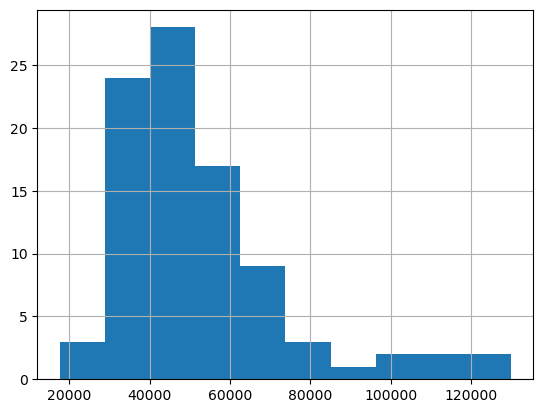

In [4]:
target = train.pop('Price')
target.hist()

In [5]:
train.head(3)

,Brand,Model,Series,Processor,Processor_Gen,RAM,Hard_Disk_Capacity,OS,Rating
0,ASUS,VivoBook,15,i3,10th,8.0,512 GB SSD,Windows 11 Home,4.3
1,DELL,Inspiron,NaN,i3,11th,8.0,1 TB HDD,Windows 11 Home,3.7
2,ASUS,VivoBook,15,i7,10th,16.0,512 GB SSD,Windows 11 Home,4.1


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91 entries, 0 to 90
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Brand               91 non-null     object 
 1   Model               82 non-null     object 
 2   Series              55 non-null     object 
 3   Processor           86 non-null     object 
 4   Processor_Gen       86 non-null     object 
 5   RAM                 85 non-null     float64
 6   Hard_Disk_Capacity  85 non-null     object 
 7   OS                  85 non-null     object 
 8   Rating              91 non-null     float64
dtypes: float64(2), object(7)
memory usage: 6.5+ KB


In [7]:
train.isnull().sum()

Brand                  0
Model                  9
Series                36
Processor              5
Processor_Gen          5
RAM                    6
Hard_Disk_Capacity     6
OS                     6
Rating                 0
dtype: int64

In [8]:
#결측치 처리(범주형)
c_col = ['Model', 'Series', 'Processor', 'Processor_Gen', 'Hard_Disk_Capacity', 'OS']
train[c_col] = train[c_col].fillna('X')
test[c_col] = test[c_col].fillna('X')

In [10]:
n_col = ['RAM']
train[n_col] = train[n_col].fillna(-1)
test[n_col] = test[n_col].fillna(-1)

### 전처리(인코딩)

In [11]:
data = pd.concat([train,test])
data = pd.get_dummies(data)

train = data[:len(train)].copy()
test = data[len(train):].copy()

print('train :', train.shape)
print('test :', test.shape)

train : (91, 119)
test : (39, 119)


In [12]:
x_train,x_val,y_train,y_val = train_test_split(
    train,
    target,
    test_size=0.2,
    random_state=0,
)

print('x_train :', x_train.shape)
print('x_val :', x_val.shape)
print('y_train :', y_train.shape)
print('y_val :', y_val.shape)

x_train : (72, 119)
x_val : (19, 119)
y_train : (72,)
y_val : (19,)


In [13]:
model = RandomForestRegressor(random_state=0)
model.fit(x_train,y_train)

pred = model.predict(x_val)
pred

array([ 58041.68,  40710.65,  39960.  ,  29390.83,  50645.18,  42199.66,
        59630.11,  37952.22,  50645.18,  94344.65,  56658.1 ,  55313.3 ,
        64828.3 ,  44725.9 , 111664.24,  64314.13,  64183.18,  63411.64,
        88967.81])

In [15]:
r2 = r2_score(y_val, pred)
print('r2 :', r2)

r2 : 0.7496764602229047


### 성능 개선

In [16]:
train = pd.read_csv('laptop_train.csv')
test = pd.read_csv('laptop_test.csv')
target = train.pop('Price')

In [17]:
#컬럼삭제('Series') - 결측치가 40%에 육박하여서 삭제
train = train.drop('Series', axis=1)
test = test.drop('Series', axis=1)

In [18]:
#컬럼삭제('Model') - 희소값이 많고 브랜드와 중복되는 요소임으로 삭제
train = train.drop('Model', axis=1)
test = test.drop('Model', axis=1)

In [19]:
train.isnull().sum()

Brand                 0
Processor             5
Processor_Gen         5
RAM                   6
Hard_Disk_Capacity    6
OS                    6
Rating                0
dtype: int64

In [20]:
c_col = ['Processor', 'Processor_Gen', 'Hard_Disk_Capacity', 'OS']
train[c_col] = train[c_col].fillna('X')
test[c_col] = test[c_col].fillna('X')

In [21]:
n_col = ['RAM']
train[n_col] = train[n_col].fillna(-1)
test[n_col] = test[n_col].fillna(-1)

In [22]:
data = pd.concat([train,test])
data = pd.get_dummies(data)

train = data[:len(train)].copy()
test = data[len(train):].copy()

print('train :', train.shape)
print('test :', test.shape)

train : (91, 56)
test : (39, 56)


In [23]:
x_train,x_val,y_train,y_val = train_test_split(
    train,
    target,
    test_size=0.2,
    random_state=0,
)

print('x_train :', x_train.shape)
print('x_val :', x_val.shape)
print('y_train :', y_train.shape)
print('y_val :', y_val.shape)

x_train : (72, 56)
x_val : (19, 56)
y_train : (72,)
y_val : (19,)


In [24]:
model = RandomForestRegressor(random_state=0)
model.fit(x_train,y_train)

pred = model.predict(x_val)
pred

array([ 64861.98,  41710.4 ,  39960.  ,  30461.45,  50599.24,  37885.72,
        61844.37,  38339.3 ,  50599.24,  94660.65,  52710.65,  49621.95,
        70778.3 ,  45671.2 , 112460.15,  68277.33,  72999.  ,  67743.37,
       108466.42])

In [25]:
r2 = r2_score(y_val, pred)
print('r2 :', r2)

r2 : 0.8042392429064131


In [26]:
submit = pd.DataFrame({'pred' : pred})
submit.to_csv('laptop_result.csv', index=False)
submit.head()

,pred
0,64861.98
1,41710.40
2,39960.00
3,30461.45
4,50599.24
